# Best Next Time to Trade

Scores every hour of the next 24h using live Bybit + Deribit data.

**What makes this different:**

1. Shows **the exact calculation** for every hour's score
2. Tells you **the best time to RUN this notebook** so you catch the window
3. Tells you **what to do RIGHT NOW** based on current time

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone, timedelta
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (12, 4)

BYBIT   = 'https://api.bybit.com'
DERIBIT = 'https://www.deribit.com/api/v2/public'
SYMBOLS = {'ETH': 'ETHUSDT', 'BTC': 'BTCUSDT'}
print('ready')

ready


## 1. Current time context

In [2]:
now = datetime.now(timezone.utc)
current_hour = now.replace(minute=0, second=0, microsecond=0)
print(f'now UTC        : {now:%Y-%m-%d %H:%M:%S}')
print(f'current hour   : {current_hour:%H:00} UTC ({now.strftime("%A")})')
print()
next_24h = [current_hour + timedelta(hours=i) for i in range(1, 25)]
print(f'planning window: {next_24h[0]:%Y-%m-%d %H:%M} to {next_24h[-1]:%Y-%m-%d %H:%M} UTC')

now UTC        : 2026-10-25 08:21:36
current hour   : 08:00 UTC (Sunday)

planning window: 2026-10-25 09:00 to 2026-10-26 08:00 UTC


## 2. Fetch 1h candles (Bybit)

500 hours = ~21 days of history. Used to compute hour-of-day profiles.

In [3]:
def fetch_klines(symbol, interval='60', limit=500):
    r = requests.get(f'{BYBIT}/v5/market/kline',
                     params={'category': 'linear', 'symbol': symbol,
                             'interval': interval, 'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list']

klines = {}
for cur, sym in SYMBOLS.items():
    try:
        k = fetch_klines(sym, '60', 500)
        rows = [{'open_time': int(x[0]),
                 'open':   float(x[1]), 'high':   float(x[2]),
                 'low':    float(x[3]), 'close':  float(x[4]),
                 'volume': float(x[5]), 'turnover': float(x[6])} for x in k]
        d = pd.DataFrame(rows)
        d['ts'] = pd.to_datetime(d.open_time, unit='ms', utc=True)
        d = d.sort_values('ts').reset_index(drop=True)
        d['hour'] = d.ts.dt.hour
        d['ret']  = d.close.pct_change()
        klines[cur] = d
        print(f'{cur}: {len(d)} candles  {d.ts.iloc[0]:%Y-%m-%d} to {d.ts.iloc[-1]:%Y-%m-%d}')
    except Exception as e:
        print(f'{cur}: failed - {e}')

ETH: 500 candles  2026-10-04 to 2026-10-25
BTC: 500 candles  2026-10-04 to 2026-10-25


## 3. Hourly profiles (THE RAW DATA)

For each hour of day (0-23), compute:

- **avg_turnover**: mean trading volume in USDT
- **avg_volatility**: std of hourly returns as %
- **avg_return**: mean return (directional bias)

These are the raw numbers that get scored.

In [4]:
profiles = {}
for cur, d in klines.items():
    p = d.groupby('hour').agg(
        avg_turnover=('turnover', 'mean'),
        avg_volatility=('ret', lambda x: x.std() * 100),
        avg_return=('ret', lambda x: x.mean() * 100),
        samples=('ret', 'count'),
    ).reindex(range(24))
    profiles[cur] = p
    print(f'\n=== {cur} hourly profile ===')
    print(p.round(2).to_string())


=== ETH hourly profile ===
      avg_turnover  avg_volatility  avg_return  samples
hour                                                   
0     6.427140e+07            0.32        0.00       21
1     8.324370e+07            0.59       -0.02       21
2     1.500795e+08            0.62        0.01       21
3     7.400278e+07            0.37       -0.06       21
4     6.708219e+07            0.38        0.07       21
5     6.858162e+07            0.44       -0.12       21
6     5.802213e+07            0.25        0.08       21
7     6.826352e+07            0.33        0.06       21
8     7.656081e+07            0.28       -0.12       21
9     8.162675e+07            0.26       -0.03       20
10    8.738424e+07            0.34       -0.11       20
11    8.633238e+07            0.29       -0.01       20
12    1.133419e+08            0.36       -0.16       20
13    1.702810e+08            0.48       -0.11       20
14    2.084389e+08            0.91        0.20       21
15    2.152784e+08  

## 4. Normalize (0 to 1 scale)

Raw numbers have different units (turnover in billions, volatility in %). Normalize each to 0-1 so they can be weighted.

```
normalized[h] = value[h] / max(value)
```

In [5]:
normalized = {}
for cur, p in profiles.items():
    n = pd.DataFrame(index=p.index)
    n['vol_score']  = p.avg_turnover   / p.avg_turnover.max()
    n['vola_score'] = p.avg_volatility / p.avg_volatility.max()
    normalized[cur] = n
    print(f'\n=== {cur} normalized (0-1) ===')
    print(n.round(3).to_string())


=== ETH normalized (0-1) ===
      vol_score  vola_score
hour                       
0         0.299       0.286
1         0.387       0.531
2         0.697       0.554
3         0.344       0.334
4         0.312       0.341
5         0.319       0.394
6         0.270       0.224
7         0.317       0.294
8         0.356       0.247
9         0.379       0.229
10        0.406       0.302
11        0.401       0.257
12        0.526       0.322
13        0.791       0.429
14        0.968       0.819
15        1.000       1.000
16        0.633       0.384
17        0.453       0.324
18        0.324       0.367
19        0.324       0.328
20        0.279       0.226
21        0.330       0.477
22        0.377       0.497
23        0.323       0.360

=== BTC normalized (0-1) ===
      vol_score  vola_score
hour                       
0         0.318       0.347
1         0.403       0.725
2         0.504       0.471
3         0.316       0.467
4         0.310       0.459
5         0.287 

## 5. Session mapping + funding + expiry penalties

Beyond volume and volatility, we penalize hours near:

- Funding settlement (00:00, 08:00, 16:00 UTC): **-0.15**
- Option expiry (Fridays 08:00 UTC): **-0.10**

In [6]:
def session(h):
    if 0 <= h < 3: return 'Asia open'
    if 3 <= h < 7: return 'Asia mid'
    if 7 <= h < 10: return 'EU open'
    if 10 <= h < 13: return 'EU mid'
    if 13 <= h < 16: return 'EU/US overlap'
    if 16 <= h < 20: return 'US afternoon'
    if 20 <= h < 22: return 'US close'
    return 'Dead zone'

SESSION_QUALITY = {
    'Asia open':     0.70,
    'Asia mid':      0.40,
    'EU open':       0.80,
    'EU mid':        0.60,
    'EU/US overlap': 1.00,
    'US afternoon':  0.70,
    'US close':      0.60,
    'Dead zone':     0.20,
}

funding_hours = [0, 8, 16]
def near_funding(dt):
    return dt.hour in funding_hours

print('session quality:')
for s, q in SESSION_QUALITY.items():
    print(f'  {s:<16} {q}')

session quality:
  Asia open        0.7
  Asia mid         0.4
  EU open          0.8
  EU mid           0.6
  EU/US overlap    1.0
  US afternoon     0.7
  US close         0.6
  Dead zone        0.2


## 6. Option expiries (Deribit)

In [7]:
def fetch_option_expiries(currency='ETH'):
    try:
        r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                         params={'currency': currency, 'kind': 'option'}, timeout=20)
        r.raise_for_status()
        data = r.json()['result']
    except Exception as e:
        print(f'option fetch failed: {e}')
        return []
    expiries = set()
    for d in data:
        parts = d['instrument_name'].split('-')
        if len(parts) != 4: continue
        try:
            dt = datetime.strptime(parts[1], '%d%b%y').replace(tzinfo=timezone.utc, hour=8)
            expiries.add(dt)
        except ValueError:
            pass
    return sorted(expiries)

expiries = fetch_option_expiries('ETH')
print(f'next {min(6, len(expiries))} ETH option expiries:')
for e in expiries[:6]:
    delta = (e - now).total_seconds() / 3600
    print(f'  {e:%Y-%m-%d %H:%M} UTC  (in {delta:.1f}h)')

next 6 ETH option expiries:
  2026-10-26 08:00 UTC  (in 23.6h)
  2026-10-27 08:00 UTC  (in 47.6h)
  2026-10-28 08:00 UTC  (in 71.6h)
  2026-10-29 08:00 UTC  (in 95.6h)
  2026-10-30 08:00 UTC  (in 119.6h)
  2026-11-06 08:00 UTC  (in 287.6h)


## 7. THE SCORE FORMULA (transparent)

For hour `h` and currency `c`:

```
score = 0.30 * normalized_volume[h]
      + 0.20 * normalized_volatility[h]
      + 0.25 * session_quality[session(h)]
      - 0.15 * (1 if near funding else 0)
      - 0.10 * (1 if within 4h of expiry else 0)
```

Range: 0.0 (worst) to 1.0 (best)

In [8]:
def calc_score(dt, cur):
    h = dt.hour
    v  = float(normalized[cur].loc[h, 'vol_score'])
    x  = float(normalized[cur].loc[h, 'vola_score'])
    s  = SESSION_QUALITY[session(h)]
    f  = 1.0 if near_funding(dt) else 0.0
    e  = 0.0
    for exp in expiries[:6]:
        hrs = (exp - dt).total_seconds() / 3600
        if 0 < hrs < 4:
            e = max(e, 1 - hrs / 4)
    raw = 0.30*v + 0.20*x + 0.25*s - 0.15*f - 0.10*e
    score = max(0.0, min(1.0, raw))
    return {
        'hour': h,
        'vol_component':  0.30 * v,
        'vola_component': 0.20 * x,
        'sess_component': 0.25 * s,
        'fund_penalty':  -0.15 * f,
        'exp_penalty':   -0.10 * e,
        'raw': raw,
        'score': score,
    }

print('calculation function ready')

calculation function ready


## 8. Example calculation - show the work

Pick the current hour and the best candidate, and show every line of the calculation.

In [9]:
cur_demo = 'ETH'
dt_demo = next_24h[0]
calc = calc_score(dt_demo, cur_demo)

print(f'EXAMPLE for {cur_demo} at {dt_demo:%Y-%m-%d %H:%M} UTC')
print(f'(hour of day = {dt_demo.hour}, session = {session(dt_demo.hour)})')
print()
print(f'  vol_score (normalized)      = {float(normalized[cur_demo].loc[dt_demo.hour, "vol_score"]):.3f}')
print(f'  vola_score (normalized)     = {float(normalized[cur_demo].loc[dt_demo.hour, "vola_score"]):.3f}')
print(f'  session_quality             = {SESSION_QUALITY[session(dt_demo.hour)]:.2f}')
print()
print('  CALCULATION:')
print(f'    0.30 * {float(normalized[cur_demo].loc[dt_demo.hour, "vol_score"]):.3f}  = {calc["vol_component"]:+.3f}  (volume contribution)')
print(f'    0.20 * {float(normalized[cur_demo].loc[dt_demo.hour, "vola_score"]):.3f}  = {calc["vola_component"]:+.3f}  (volatility contribution)')
print(f'    0.25 * {SESSION_QUALITY[session(dt_demo.hour)]:.2f}  = {calc["sess_component"]:+.3f}  (session quality)')
print(f'                = {calc["fund_penalty"]:+.3f}  (funding proximity)')
print(f'                = {calc["exp_penalty"]:+.3f}  (expiry proximity)')
print(f'                -------')
print(f'    RAW SCORE   = {calc["raw"]:+.3f}')
print(f'    FINAL       = {calc["score"]:.3f}  (clamped to 0..1)')

EXAMPLE for ETH at 2026-10-25 09:00 UTC
(hour of day = 9, session = EU open)

  vol_score (normalized)      = 0.379
  vola_score (normalized)     = 0.229
  session_quality             = 0.80

  CALCULATION:
    0.30 * 0.379  = +0.114  (volume contribution)
    0.20 * 0.229  = +0.046  (volatility contribution)
    0.25 * 0.80  = +0.200  (session quality)
                = -0.000  (funding proximity)
                = -0.000  (expiry proximity)
                -------
    RAW SCORE   = +0.360
    FINAL       = 0.360  (clamped to 0..1)


## 9. Score every hour of next 24h (per currency)

In [10]:
rows = []
for cur in SYMBOLS:
    if cur not in normalized: continue
    for dt in next_24h:
        c = calc_score(dt, cur)
        rows.append({
            'currency': cur,
            'datetime': dt,
            'hour': dt.hour,
            'weekday': dt.strftime('%a'),
            'session': session(dt.hour),
            'vol_comp': c['vol_component'],
            'vola_comp': c['vola_component'],
            'sess_comp': c['sess_component'],
            'fund_pen': c['fund_penalty'],
            'exp_pen': c['exp_penalty'],
            'score': c['score'],
        })

plan = pd.DataFrame(rows)
print(f'scored {len(plan)} hours')
print()
print('breakdown of top 10 hours for ETH:')
top_eth = plan[plan.currency == 'ETH'].sort_values('score', ascending=False).head(10)
print(top_eth[['datetime', 'hour', 'session', 'vol_comp', 'vola_comp',
                'sess_comp', 'fund_pen', 'exp_pen', 'score']].to_string(index=False))

scored 48 hours

breakdown of top 10 hours for ETH:
                 datetime  hour       session  vol_comp  vola_comp  sess_comp  fund_pen  exp_pen    score
2026-10-25 15:00:00+00:00    15 EU/US overlap  0.300000   0.200000      0.250      -0.0     -0.0 0.750000
2026-10-25 14:00:00+00:00    14 EU/US overlap  0.290469   0.163732      0.250      -0.0     -0.0 0.704201
2026-10-25 13:00:00+00:00    13 EU/US overlap  0.237294   0.085899      0.250      -0.0     -0.0 0.573193
2026-10-26 02:00:00+00:00     2     Asia open  0.209142   0.110818      0.175      -0.0     -0.0 0.494960
2026-10-26 01:00:00+00:00     1     Asia open  0.116004   0.106288      0.175      -0.0     -0.0 0.397292
2026-10-25 17:00:00+00:00    17  US afternoon  0.135958   0.064786      0.175      -0.0     -0.0 0.375744
2026-10-25 12:00:00+00:00    12        EU mid  0.157947   0.064495      0.150      -0.0     -0.0 0.372442
2026-10-25 09:00:00+00:00     9       EU open  0.113750   0.045787      0.200      -0.0     -0.0 0.3

## 10. BEST NEXT TIME - the answer

Two blocks:

1. **When to run this notebook next** (so you catch the window)
2. **When to actually trade** (the best hour)

In [11]:
print('=' * 72)
print('BEST NEXT TIME TO TRADE')
print('=' * 72)

for cur in plan.currency.unique():
    sub = plan[plan.currency == cur].sort_values('score', ascending=False)
    if sub.empty: continue
    best   = sub.iloc[0]
    second = sub.iloc[1] if len(sub) > 1 else None
    worst  = sub.iloc[-1]
    hrs_to_best = (best.datetime - now).total_seconds() / 3600

    print(f'\n{cur}:')
    print(f'  Score 1st : {best.score:.3f}   {best.datetime:%a %Y-%m-%d %H:%M} UTC  ({best.session})')
    print(f'              starts in {hrs_to_best:.1f} hours')
    print(f'  Score 2nd : {second.score:.3f}   {second.datetime:%a %Y-%m-%d %H:%M} UTC  ({second.session})')
    print(f'  Score bad : {worst.score:.3f}   {worst.datetime:%a %Y-%m-%d %H:%M} UTC  ({worst.session}) - AVOID')

BEST NEXT TIME TO TRADE

ETH:
  Score 1st : 0.750   Sun 2026-10-25 15:00 UTC  (EU/US overlap)
              starts in 6.6 hours
  Score 2nd : 0.704   Sun 2026-10-25 14:00 UTC  (EU/US overlap)
  Score bad : 0.172   Mon 2026-10-26 00:00 UTC  (Asia open) - AVOID

BTC:
  Score 1st : 0.750   Sun 2026-10-25 14:00 UTC  (EU/US overlap)
              starts in 5.6 hours
  Score 2nd : 0.694   Sun 2026-10-25 15:00 UTC  (EU/US overlap)
  Score bad : 0.188   Mon 2026-10-26 06:00 UTC  (Asia mid) - AVOID


## 11. BEST TIME TO RUN THIS NOTEBOOK

You should re-run this notebook **1 hour before the best trade window opens** so the data is fresh. This cell computes that run time for you.

In [12]:
print('=' * 72)
print('WHEN TO RUN THIS NOTEBOOK NEXT')
print('=' * 72)

for cur in plan.currency.unique():
    sub = plan[plan.currency == cur].sort_values('score', ascending=False)
    if sub.empty: continue
    best = sub.iloc[0]
    run_time = best.datetime - timedelta(hours=1)
    hrs_until_run = (run_time - now).total_seconds() / 3600

    print(f'\n{cur}:')
    print(f'  Best trade window : {best.datetime:%a %Y-%m-%d %H:00} UTC')
    print(f'  Run this notebook : {run_time:%a %Y-%m-%d %H:00} UTC')
    print(f'  That is           : {hrs_until_run:.1f} hours from now')
    if hrs_until_run < 0:
        print(f'  NOTE: run time already passed - run again tomorrow')
    elif hrs_until_run < 2:
        print(f'  NOTE: run soon - the window opens in ~1 hour')
    else:
        print(f'  NOTE: set an alert for {hrs_until_run:.0f}h from now')

WHEN TO RUN THIS NOTEBOOK NEXT

ETH:
  Best trade window : Sun 2026-10-25 15:00 UTC
  Run this notebook : Sun 2026-10-25 14:00 UTC
  That is           : 5.6 hours from now
  NOTE: set an alert for 6h from now

BTC:
  Best trade window : Sun 2026-10-25 14:00 UTC
  Run this notebook : Sun 2026-10-25 13:00 UTC
  That is           : 4.6 hours from now
  NOTE: set an alert for 5h from now


## 12. Should I trade RIGHT NOW?

Compares the current hour to the best hour of the next 24h.

If current score is close to best, trade now. Otherwise wait.

In [13]:
print('=' * 72)
print('RIGHT NOW CHECK')
print('=' * 72)
print()
print(f'Current time: {now:%Y-%m-%d %H:%M} UTC (hour {now.hour}, {session(now.hour)})')

for cur in plan.currency.unique():
    sub = plan[plan.currency == cur].sort_values('score', ascending=False)
    best = sub.iloc[0]
    cur_score = calc_score(current_hour, cur)
    pct_of_best = cur_score['score'] / best.score if best.score > 0 else 0

    print(f'\n{cur}:')
    print(f'  current hour score : {cur_score["score"]:.3f}')
    print(f'  best hour score    : {best.score:.3f}  ({best.datetime:%a %H:%M} UTC)')
    print(f'  current is         : {pct_of_best*100:.0f}% of best')
    if pct_of_best > 0.85:
        print(f'  VERDICT: trade NOW - this is near-optimal')
    elif pct_of_best > 0.65:
        print(f'  VERDICT: acceptable - good enough if you have a strong signal')
    elif pct_of_best > 0.40:
        print(f'  VERDICT: wait - {cur_score["score"]/best.score if best.score > 0 else 0:.0f}% of optimal')
    else:
        print(f'  VERDICT: definitely WAIT - poor timing')

RIGHT NOW CHECK

Current time: 2026-10-25 08:21 UTC (hour 8, EU open)

ETH:
  current hour score : 0.206
  best hour score    : 0.750  (Sun 15:00 UTC)
  current is         : 27% of best
  VERDICT: definitely WAIT - poor timing

BTC:
  current hour score : 0.231
  best hour score    : 0.750  (Sun 14:00 UTC)
  current is         : 31% of best
  VERDICT: definitely WAIT - poor timing


## 13. Visual comparison - all 24 hours

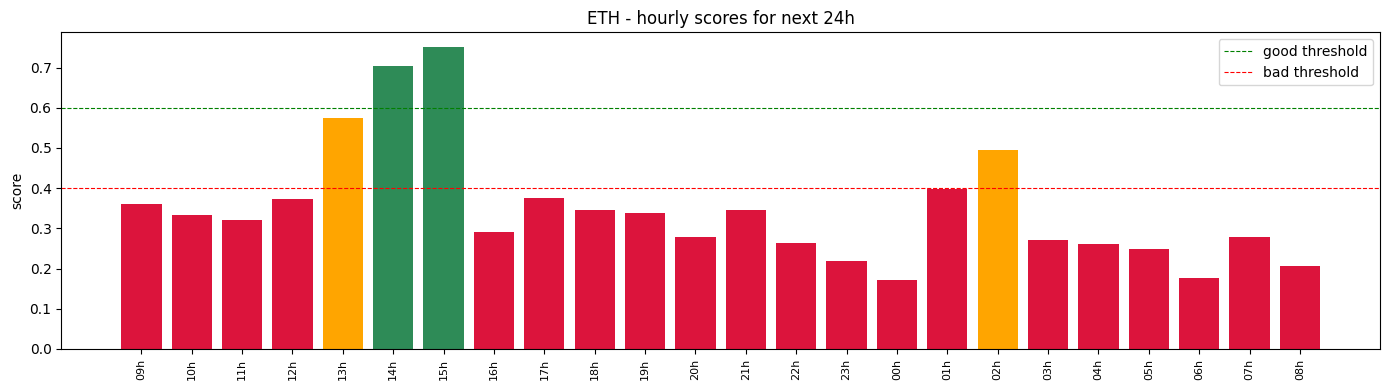

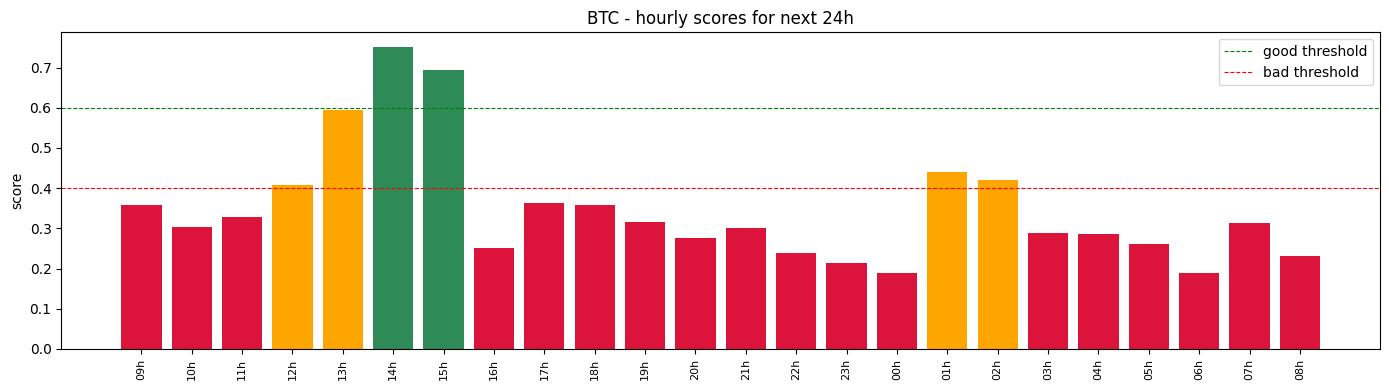

In [14]:
for cur in plan.currency.unique():
    sub = plan[plan.currency == cur].sort_values('datetime')
    fig, ax = plt.subplots(figsize=(14, 4))
    colors = ['seagreen' if s > 0.6 else 'orange' if s > 0.4 else 'crimson' for s in sub.score]
    ax.bar(range(len(sub)), sub.score, color=colors)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels([f'{r.datetime:%H}h' for _, r in sub.iterrows()], rotation=90, fontsize=8)
    ax.axhline(0.6, color='green', lw=0.8, ls='--', label='good threshold')
    ax.axhline(0.4, color='red', lw=0.8, ls='--', label='bad threshold')
    ax.set_title(f'{cur} - hourly scores for next 24h')
    ax.set_ylabel('score')
    ax.legend()
    plt.tight_layout(); plt.show()

## 14. Full 24h plan (with actual score breakdown)

In [15]:
for cur in plan.currency.unique():
    sub = plan[plan.currency == cur].sort_values('datetime')
    print(f'\n--- {cur} next 24h ---')
    print(f"{'date':<18} {'hour':<4} {'session':<16} {'vol':<6} {'vola':<6} {'sess':<6} {'fund':<6} {'exp':<6} {'SCORE':<6}")
    print('-' * 90)
    for _, r in sub.iterrows():
        mark = '***' if r.score > 0.7 else ('  .' if r.score < 0.3 else '   ')
        print(f"{r.datetime:%a %m-%d %H:%M}  {r.hour:>2}  {r.session:<16} "
              f"{r.vol_comp:.2f}  {r.vola_comp:.2f}  {r.sess_comp:.2f}  "
              f"{r.fund_pen:+.2f}  {r.exp_pen:+.2f}  {r.score:.3f} {mark}")


--- ETH next 24h ---
date               hour session          vol    vola   sess   fund   exp    SCORE 
------------------------------------------------------------------------------------------
Sun 10-25 09:00   9  EU open          0.11  0.05  0.20  -0.00  -0.00  0.360    
Sun 10-25 10:00  10  EU mid           0.12  0.06  0.15  -0.00  -0.00  0.332    
Sun 10-25 11:00  11  EU mid           0.12  0.05  0.15  -0.00  -0.00  0.322    
Sun 10-25 12:00  12  EU mid           0.16  0.06  0.15  -0.00  -0.00  0.372    
Sun 10-25 13:00  13  EU/US overlap    0.24  0.09  0.25  -0.00  -0.00  0.573    
Sun 10-25 14:00  14  EU/US overlap    0.29  0.16  0.25  -0.00  -0.00  0.704 ***
Sun 10-25 15:00  15  EU/US overlap    0.30  0.20  0.25  -0.00  -0.00  0.750 ***
Sun 10-25 16:00  16  US afternoon     0.19  0.08  0.17  -0.15  -0.00  0.292   .
Sun 10-25 17:00  17  US afternoon     0.14  0.06  0.17  -0.00  -0.00  0.376    
Sun 10-25 18:00  18  US afternoon     0.10  0.07  0.17  -0.00  -0.00  0.346    
Sun 

## 15. Save plan as CSV

In [16]:
from pathlib import Path
try:
    out = Path(r'D:\\Projects\\done\\eth_bot\\eth_bot_v2') / 'reports'
    out.mkdir(parents=True, exist_ok=True)
    path = out / f'timing_plan_{now:%Y%m%d_%H%M}.csv'
    plan.to_csv(path, index=False)
    print('saved:', path)
except Exception as e:
    print('save failed:', e)

saved: D:\Projects\done\eth_bot\eth_bot_v2\reports\timing_plan_20261025_0821.csv


## 16. Interpretation guide

In [17]:
print('=' * 72)
print('HOW TO USE THIS')
print('=' * 72)
print()
print('SCORE meanings:')
print('  > 0.70  EXCELLENT - best hours, enter here')
print('  0.60-0.70  GOOD - solid entry')
print('  0.40-0.60  NEUTRAL - possible but not ideal')
print('  < 0.40  AVOID - thin liquidity or event risk')
print()
print('ACTION workflow:')
print('  1. Scroll to section 10 (BEST NEXT TIME)')
print('  2. Note the best hour for tomorrow')
print('  3. Note the run time from section 11 (best hour - 1h)')
print('  4. Set phone alert for run time')
print('  5. At run time: rerun this notebook for fresh data')
print('  6. At best hour: run 01_options_buyer_analysis for the contract')
print('  7. Execute if your signal agrees')
print()
print('DONE.')

HOW TO USE THIS

SCORE meanings:
  > 0.70  EXCELLENT - best hours, enter here
  0.60-0.70  GOOD - solid entry
  0.40-0.60  NEUTRAL - possible but not ideal
  < 0.40  AVOID - thin liquidity or event risk

ACTION workflow:
  1. Scroll to section 10 (BEST NEXT TIME)
  2. Note the best hour for tomorrow
  3. Note the run time from section 11 (best hour - 1h)
  4. Set phone alert for run time
  5. At run time: rerun this notebook for fresh data
  6. At best hour: run 01_options_buyer_analysis for the contract
  7. Execute if your signal agrees

DONE.
